# Лабораторная работа 3. Решающее дерево

Цель эксперимента — сравнить sklearn и собственную реализацию на классификации переписчиков и оценке мощности волновой фермы. Все варианты оцениваются на одних и тех же объектах.

## Задачи и разбиение


**Avila** содержит десять признаков геометрии текстовых фрагментов латинской рукописи XII века. Классификация по переписчикам позволяет предварительно распределять фрагменты перед проверкой палеографом. Используется разбиение UCI. Номера страниц в признаках отсутствуют, поэтому результаты относятся к этому протоколу и одному манускрипту. [Источник и словарь признаков](https://doi.org/10.24432/C5K02X)

**Wave Energy Converters · Tasmania.** По координатам 16 преобразователей требуется оценить суммарную мощность фермы. Такой прогноз может ускорить отбор вариантов перед запуском гидродинамического симулятора. 16 индивидуальных мощностей исключены: их сумма практически равна целевой переменной. Разбиение учитывает группы конфигураций по координатам, округлённым до 10 м. Соседние конфигурации по разные стороны границы округления могут оказаться в разных частях. Данные охватывают один волновой сценарий. [Источник и схема данных](https://doi.org/10.24432/C5831S)

Обе задачи используют по три внутренних фолда. В каждом фолде масштабирование и модель подгоняются только по его обучающей части. Holdout одинаков для всех пяти работ и используется после выбора конфигураций.

In [1]:
# Загружаем фиксированные разбиения и общие функции эксперимента.
import pandas as pd
from IPython.display import Markdown, display
from labkit.data import load_tasks
from labkit.experiments import (
    comparison_text, describe_data, evaluate_holdout, plot_predictions,
    plot_training, primary_metric, save_scores, select_candidates,
)

LAB = 3
tasks = load_tasks()
display(describe_data(tasks))
for task in tasks:
    display(pd.Series(task.audit, name=task.title).to_frame())

,задача,строк в исходных файлах,train,test,исходные признаки,разбиение
0,Avila — автор фрагмента,20867,10430,10437,10,Официальные train/test; 3 стратифицированных ф...
1,Tasmania — суммарная мощность (МВт),72000,5762,1438,32,Групповой holdout 20% групп; 3 групповых фолда...


,Avila — автор фрагмента
Точных совпадений векторов признаков между train/test,0


,Tasmania — суммарная мощность (МВт)
Строк после проверки диапазонов и пропусков,72000
Точных уникальных конфигураций,72000
Строк в воспроизводимой подвыборке,7200
Групп в подвыборке (округление координат до 10 м),7183


## Выбор метрик


**Avila.** Macro-F1 усредняет F1 по всем 12 классам, сохраняя вклад редких переписчиков. Balanced accuracy — средняя полнота по классам. Accuracy показывает долю верных ответов по всем фрагментам.

**Tasmania.** MAE в МВт показывает средний абсолютный промах. RMSE в тех же единицах сильнее учитывает большие ошибки. R² отражает долю объяснённой вариации относительно среднего отклика теста и может быть отрицательным.

Для проверки полезности моделей используется простой ориентир. Классификационный dummy всегда выбирает самый частый класс train, регрессионный — медиану train. Основные метрики для выбора конфигурации — macro-F1 (выше) и MAE (ниже).

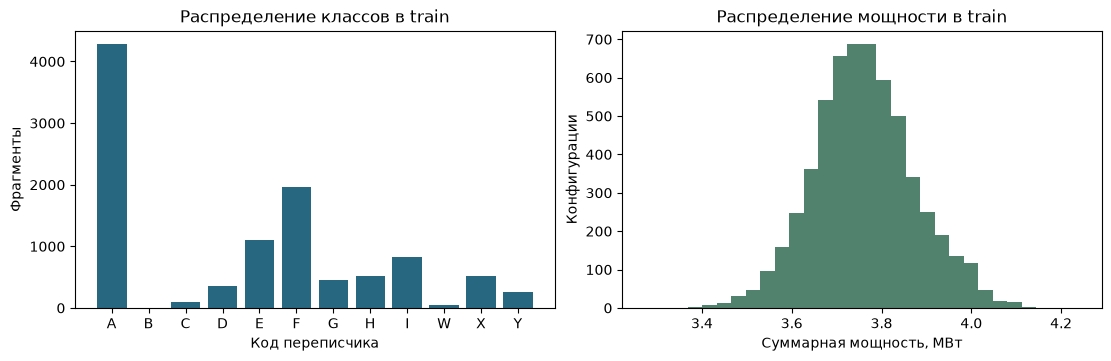

In [2]:
# Изучаем дисбаланс классов и масштаб мощности на обучающих данных.
plot_training(tasks)

## Библиотечный бейзлайн

DecisionTreeClassifier использует Gini, DecisionTreeRegressor — квадратичную ошибку. Глубина изначально не ограничена, в минимальном листе может быть один объект.

## Гипотезы и кросс-валидация

Глубина и минимальный размер листа регулируют локальную сложность дерева. Проверяем, уменьшает ли это переобучение. В классификации также меняем веса классов, чтобы ошибки редких классов сильнее влияли на разбиения. В регрессии сравниваем сырые координаты и компактный набор признаков геометрии.

В сетку включён бейзлайн. При равенстве средних метрик приоритет получает первая конфигурация. В таблицах приведены оценки каждого фолда и стандартное отклонение между фолдами.

In [3]:
# Проверяем гипотезы на трёх внутренних фолдах и фиксируем победителей.
selections = select_candidates(LAB, tasks)
for task in tasks:
    display(Markdown(f"**{task.title} · {primary_metric(task)}**"))
    display(selections[task.key][2].round(5))

**Avila — автор фрагмента · macro_f1**

,гипотеза,признаки,настройки,CV среднее,CV σ,фолд 1,фолд 2,фолд 3,выбран
0,Бейзлайн,raw,{},0.90412,0.01923,0.88252,0.91941,0.91042,False
1,Глубина 12 и минимум 3 в листе,raw,"{""max_depth"": 12, ""min_samples_leaf"": 3}",0.79098,0.06741,0.74606,0.75839,0.86850,False
2,Только веса классов,raw,"{""class_weight"": ""balanced""}",0.92155,0.05135,0.87383,0.91493,0.97589,True
3,Веса классов и ограничения дерева,raw,"{""max_depth"": 12, ""min_samples_leaf"": 3, ""clas...",0.74201,0.04604,0.69044,0.77898,0.75660,False
4,Минимум 2 в листе,raw,"{""min_samples_leaf"": 2}",0.87593,0.01775,0.85881,0.87472,0.89426,False


**Tasmania — суммарная мощность (МВт) · mae_mw**

,гипотеза,признаки,настройки,CV среднее,CV σ,фолд 1,фолд 2,фолд 3,выбран
0,Бейзлайн,raw,{},0.07779,0.00100,0.07728,0.07895,0.07715,False
1,Глубина 12 и минимум 3 в листе,raw,"{""max_depth"": 12, ""min_samples_leaf"": 3}",0.07114,0.00091,0.07100,0.07031,0.07211,False
2,Геометрия,geometry,{},0.06895,0.00262,0.06597,0.07093,0.06993,False
3,Геометрия и ограничения дерева,geometry,"{""max_depth"": 12, ""min_samples_leaf"": 3}",0.06340,0.00236,0.06069,0.06502,0.06449,True


## Оценка sklearn на отложенной выборке

Переобучаем бейзлайн и победителя CV на всём train. В итоговом сравнении сохраняем фактический результат даже при снижении качества на holdout.

In [4]:
# Получаем holdout-метрики и сохраняем прогнозы для анализа ошибок.
results = evaluate_holdout(LAB, tasks, selections)
for task in tasks:
    table, _ = results[task.key]
    base = table.loc[table["version"].isin(["dummy", "sklearn baseline", "sklearn tuned"])]
    display(Markdown(f"**{task.title}**"))
    display(base.dropna(axis=1, how="all").drop(columns=["lab", "task", "algorithm"]).round(5))

**Avila — автор фрагмента**

,version,candidate,fit_s,predict_s,macro_f1,balanced_accuracy,accuracy
0,dummy,Мода,NaN,NaN,0.04852,0.08333,0.41065
1,sklearn baseline,Бейзлайн,0.11304,0.00437,0.95820,0.96451,0.96924
2,sklearn tuned,Только веса классов,0.15146,0.00523,0.98517,0.98362,0.98726


**Tasmania — суммарная мощность (МВт)**

,version,candidate,fit_s,predict_s,mae_mw,rmse_mw,r2
0,dummy,Медиана,NaN,NaN,0.08752,0.11228,-0.00000
1,sklearn baseline,Бейзлайн,0.28979,0.00114,0.07690,0.10132,0.18567
2,sklearn tuned,Геометрия и ограничения дерева,0.25728,0.03943,0.06159,0.08233,0.46229


## Собственная реализация

Собственный CART сортирует значения каждого рассматриваемого признака в узле и перебирает пороги между различными соседними значениями. Для классификации качество разреза определяется суммой взвешенных Gini дочерних узлов, для регрессии — суммой квадратов отклонений от средних. Лист возвращает взвешенное распределение классов или средний отклик. Numba ускоряет поиск порогов и обход готового дерева.

Параметры и преобразования переносятся из библиотечного бейзлайна и лучшей библиотечной конфигурации соответственно. Повторного подбора по holdout нет. [Код оценивателей](labkit/models.py)

In [5]:
# Сопоставляем две собственные версии с эквивалентными конфигурациями sklearn.
for task in tasks:
    table, _ = results[task.key]
    models = table.loc[table["version"] != "dummy"]
    display(Markdown(f"**{task.title}**"))
    display(models.dropna(axis=1, how="all").drop(columns=["lab", "task", "algorithm"]).round(5))

**Avila — автор фрагмента**

,version,candidate,fit_s,predict_s,macro_f1,balanced_accuracy,accuracy
1,sklearn baseline,Бейзлайн,0.11304,0.00437,0.95820,0.96451,0.96924
2,sklearn tuned,Только веса классов,0.15146,0.00523,0.98517,0.98362,0.98726
3,own baseline,Бейзлайн,0.61913,0.46028,0.95867,0.96407,0.96982
4,own tuned,Только веса классов,0.20590,0.00343,0.97465,0.96681,0.98783


**Tasmania — суммарная мощность (МВт)**

,version,candidate,fit_s,predict_s,mae_mw,rmse_mw,r2
1,sklearn baseline,Бейзлайн,0.28979,0.00114,0.07690,0.10132,0.18567
2,sklearn tuned,Геометрия и ограничения дерева,0.25728,0.03943,0.06159,0.08233,0.46229
3,own baseline,Бейзлайн,0.84131,0.09869,0.07740,0.10210,0.17309
4,own tuned,Геометрия и ограничения дерева,0.32359,0.03855,0.06161,0.08233,0.46230


## Диагностика ошибок

Матрица ошибок нормирована по истинному классу. Точки на графике мощности сравниваются с диагональю идеального прогноза. Обе визуализации относятся к варианту sklearn, выбранному по CV.

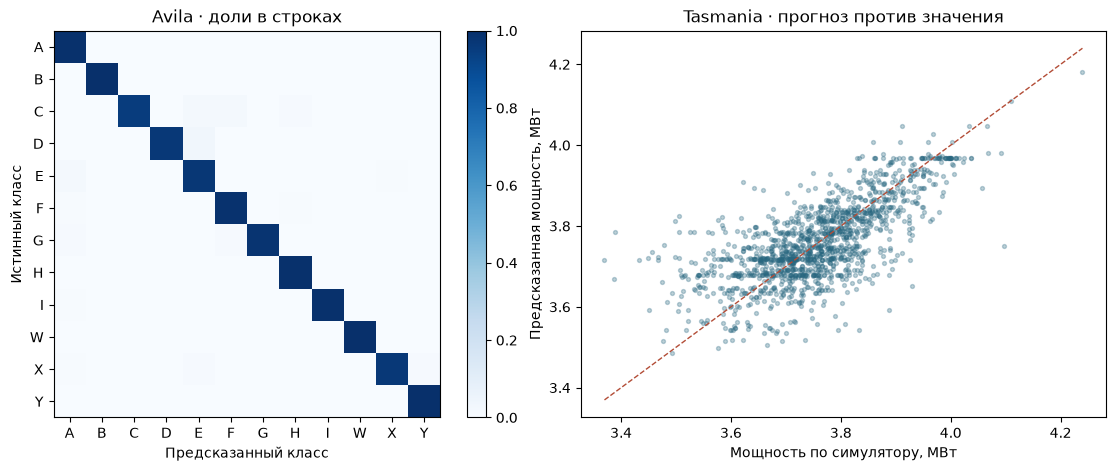

In [6]:
# Визуализируем ошибки классификации и отклонения мощности на holdout.
plot_predictions(tasks, results)

## Выводы

In [7]:
# Формируем вывод из измеренных метрик и экспортируем входные данные для сводки.
display(Markdown(comparison_text(tasks, results, selections)))
relative_path = save_scores(LAB, results)
print(f"Метрики сохранены в {relative_path.as_posix()}")

**Avila — автор фрагмента.** По CV выбран вариант «Только веса классов» (macro-F1 0.9215, бейзлайн 0.9041). На holdout macro-F1 sklearn улучшился относительно бейзлайна: 0.9582 → 0.9852. Собственная реализация: 0.9587 → 0.9747. Разница собственной модели и sklearn macro-F1: +0.0005 в бейзлайне, -0.0105 после настройки.

**Tasmania — суммарная мощность (МВт).** По CV выбран вариант «Геометрия и ограничения дерева» (MAE 0.0634 МВт, бейзлайн 0.0778 МВт). На holdout MAE sklearn улучшился относительно бейзлайна: 0.0769 → 0.0616 МВт. Собственная реализация: 0.0774 → 0.0616 МВт. Разница собственной модели и sklearn MAE: +0.0005 МВт в бейзлайне, +0.0000 МВт после настройки.

Метрики сохранены в results/lab_03.csv
